# 📜 Next Word Predictor using LSTM & Tiny Shakespeare Dataset
### A Complete End-to-End Deep Learning Natural Language Processing Pipeline

---

## 🎯 Project Overview
In this notebook, we build, train, evaluate, and test a **Word-Level Next Word Predictor** trained on William Shakespeare's writings (**Tiny Shakespeare** dataset).

The deep learning pipeline follows these steps:
1. **Data Acquisition**: Downloading and reading the raw Tiny Shakespeare text (~40,000 lines).
2. **Cleaning & Preprocessing**: Lowercasing, removing noise, handling contractions, and line splitting.
3. **Tokenization**: Fitting Keras `Tokenizer`, vocabulary building, and index mapping.
4. **N-Gram Sequence Generation & Pre-Padding**: Creating cumulative token sequences and applying `pad_sequences(..., padding='pre')`.
5. **Feature & Label Separation**: Splitting predictors ($X$) and next-word targets ($y$).
6. **Model Architecture**:
   - **Layer 1**: `Embedding` (Token index $\to$ Dense vector representation)
   - **Layer 2**: Single `LSTM` layer (Recurrent sequential context modeling)
   - **Layer 3**: `Dense` layer with Softmax activation (Vocabulary probability distribution)
7. **Model Training & Callbacks**: Training with Early Stopping and Learning Rate scheduling.
8. **Evaluation & Training Curves**: Visualizing categorical loss and accuracy over epochs.
9. **Multi-Word Prediction Engine**: Predicting not just 1 word, but multiple continuous words ($K$ steps) with greedy and temperature-based stochastic sampling.
10. **Exporting Artifacts**: Saving model weights and tokenizer for interactive UI deployment.


---
## 1. Environment Setup & Library Imports
We import TensorFlow, Keras sequence utilities, model layers, numerical computing tools, and plotting utilities.


In [1]:
import os
import re
import json
import pickle
import requests
import numpy as np
import matplotlib.pyplot as plt

# Suppress TensorFlow debug logs
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print(f"TensorFlow Version: {tf.__version__}")
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))}")


TensorFlow Version: 2.21.0
Num GPUs Available: 0


---
## 2. Dataset Acquisition & Loading: Tiny Shakespeare
The **Tiny Shakespeare** dataset consists of approximately 1.1 MB of text containing excerpts from Shakespeare's famous plays (Hamlet, Coriolanus, Julius Caesar, etc.).
We download it directly from Andrej Karpathy's repository.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_FILE = "tiny_shakespeare.txt"

def load_shakespeare_data(file_path=DATA_FILE, url=DATA_URL):
    """Loads text from local file if present, else downloads from URL."""
    if os.path.exists(file_path):
        print(f"[*] Found existing dataset file: '{file_path}'")
        with open(file_path, "r", encoding="utf-8") as f:
            text = f.read()
    else:
        print(f"[*] Downloading Tiny Shakespeare from {url}...")
        try:
            res = requests.get(url, timeout=15)
            res.raise_for_status()
            text = res.text
            with open(file_path, "w", encoding="utf-8") as f:
                f.write(text)
            print(f"[+] Download complete! Saved to '{file_path}'")
        except Exception as e:
            print(f"[-] Could not download ({e}). Reading fallback sample...")
            # Fallback Shakespeare sample if offline
            text = """
            First Citizen:
            Before we proceed any further, hear me speak.
            All:
            Speak, speak.
            First Citizen:
            You are all resolved rather to die than to famish?
            All:
            Resolved. resolved.
            To be, or not to be, that is the question:
            Whether 'tis nobler in the mind to suffer
            The slings and arrows of outrageous fortune,
            Or to take arms against a sea of troubles
            And by opposing end them.
            Shall I compare thee to a summer's day?
            Thou art more lovely and more temperate.
            """
    return text

raw_text = load_shakespeare_data()

print(f"Total Characters: {len(raw_text):,}")
print(f"Total Lines:      {len(raw_text.splitlines()):,}")
print(f"Total Raw Words:  {len(raw_text.split()):,}")

print("\n--- Sample First 400 Characters ---")
print(raw_text[:400])


[*] Found existing dataset file: 'tiny_shakespeare.txt'
Total Characters: 1,115,394
Total Lines:      40,000
Total Raw Words:  202,651

--- Sample First 400 Characters ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


---
## 3. Data Cleaning & Text Preprocessing
For word-level language modeling:
1. Convert all characters to lowercase.
2. Remove standalone speaker annotations (e.g. `First Citizen:`).
3. Filter out punctuation noise while keeping apostrophes for Shakespearean contractions (e.g., `'tis`, `we'll`).
4. Keep lines with at least 2 words (a minimum required to predict a next word).

> **Note on Training Subset**: Tiny Shakespeare has ~200,000 words. Generating every possible n-gram across all 40,000 lines creates millions of sequences, which can exceed memory limits during local training. We define `SAMPLE_LINES = 1500` (or `2000`) for fast and stable local training, which can be adjusted higher on GPUs.


In [3]:
SAMPLE_LINES = 1500  # Adjust according to available RAM/GPU capacity

def clean_and_split_corpus(text, max_lines=SAMPLE_LINES):
    lines = text.split("\n")
    if max_lines and max_lines < len(lines):
        print(f"[*] Selecting first {max_lines:,} lines for training efficiency.")
        lines = lines[:max_lines]

    cleaned_lines = []
    for line in lines:
        line = line.strip().lower()
        if not line:
            continue
        # Strip speaker labels (e.g. "first citizen:")
        line = re.sub(r'^[a-z0-9\s]+:$', '', line)
        # Strip unusual characters, keep alphanumeric and apostrophes
        line = re.sub(r"[^a-zA-Z0-9\s']", " ", line)
        # Collapse multiple spaces
        line = re.sub(r"\s+", " ", line).strip()
        # Keep lines with at least 2 words
        if len(line.split()) >= 2:
            cleaned_lines.append(line)

    return cleaned_lines

cleaned_corpus = clean_and_split_corpus(raw_text, max_lines=SAMPLE_LINES)

print(f"Total valid cleaned lines: {len(cleaned_corpus):,}")
print("\n--- First 5 Cleaned Lines ---")
for i, l in enumerate(cleaned_corpus[:5]):
    print(f"[{i+1}] {l}")


[*] Selecting first 1,500 lines for training efficiency.
Total valid cleaned lines: 929

--- First 5 Cleaned Lines ---
[1] before we proceed any further hear me speak
[2] speak speak
[3] you are all resolved rather to die than to famish
[4] resolved resolved
[5] first you know caius marcius is chief enemy to the people


---
## 4. Tokenization & Vocabulary Building
We use Keras `Tokenizer` to map each distinct word in our vocabulary to a unique integer index.
- We add an `<OOV>` (Out-Of-Vocabulary) token.
- Total words is calculated as `len(tokenizer.word_index) + 1` (index 0 is reserved for padding).


In [4]:
# Initialize Tokenizer
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(cleaned_corpus)

total_words = len(tokenizer.word_index) + 1
print(f"Total Unique Vocabulary Tokens (+1 for padding index 0): {total_words:,}")

# Inspect first 15 words in vocabulary
print("\nSample Vocabulary Mapping (first 15 words):")
sample_items = list(tokenizer.word_index.items())[:15]
for word, idx in sample_items:
    print(f"  Token: '{word:<12}' -> ID: {idx}")


Total Unique Vocabulary Tokens (+1 for padding index 0): 1,787

Sample Vocabulary Mapping (first 15 words):
  Token: '<OOV>       ' -> ID: 1
  Token: 'the         ' -> ID: 2
  Token: 'you         ' -> ID: 3
  Token: 'to          ' -> ID: 4
  Token: 'i           ' -> ID: 5
  Token: 'and         ' -> ID: 6
  Token: 'of          ' -> ID: 7
  Token: 'a           ' -> ID: 8
  Token: 'in          ' -> ID: 9
  Token: 'that        ' -> ID: 10
  Token: 'your        ' -> ID: 11
  Token: 'not         ' -> ID: 12
  Token: 'with        ' -> ID: 13
  Token: 'my          ' -> ID: 14
  Token: 'it          ' -> ID: 15


---
## 5. N-Gram Sequence Generation & Pre-Padding
For every sentence, we generate incremental **n-grams**:
- Example sentence: `"to be or not to be"`
- Generated sequences:
  - `[to, be]`
  - `[to, be, or]`
  - `[to, be, or, not]`
  - `[to, be, or, not, to]`
  - `[to, be, or, not, to, be]`

### Why Pre-Padding (`padding='pre'`)?
In recurrent neural networks like LSTMs, states are updated sequentially from left to right.
By placing the zero-padding at the **beginning** of the sequence (`padding='pre'`), the actual words reside in the final time steps right before the output prediction. This prevents the LSTM's hidden state from being diluted by trailing zeros!


In [5]:
# Step A: Generate N-gram Sequences
input_sequences = []

for line in cleaned_corpus:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_seq = token_list[: i + 1]
        input_sequences.append(n_gram_seq)

print(f"Total N-gram Input Sequences: {len(input_sequences):,}")

# Step B: Determine Maximum Sequence Length
max_sequence_len = max(len(seq) for seq in input_sequences)
print(f"Max Sequence Length across corpus: {max_sequence_len}")

# Step C: Apply Pre-Padding
padded_sequences = np.array(
    pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre')
)

print(f"Padded Sequences Matrix Shape: {padded_sequences.shape}")

print("\n--- Sample Pre-Padded Sequence (Tokens) ---")
print(padded_sequences[0])
sample_words = [tokenizer.index_word.get(idx, "<PAD>") for idx in padded_sequences[0]]
print("Word Equivalent:")
print(sample_words)


Total N-gram Input Sequences: 5,940
Max Sequence Length across corpus: 12
Padded Sequences Matrix Shape: (5940, 12)

--- Sample Pre-Padded Sequence (Tokens) ---
[  0   0   0   0   0   0   0   0   0   0 116  21]
Word Equivalent:
['<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', 'before', 'we']


---
## 6. Feature ($X$) and Target Label ($y$) Separation
We split our pre-padded array:
- **Input Features ($X$)**: All tokens except the last token $\to$ `padded_sequences[:, :-1]` (shape: `(N, max_sequence_len - 1)`)
- **Target Label ($y$)**: The final token $\to$ `padded_sequences[:, -1]` (shape: `(N,)`)

We train with `sparse_categorical_crossentropy` loss. This directly accepts integer target indices without having to allocate gigabytes of memory for one-hot matrices.


In [6]:
# Extract X and y
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print(f"X (Input Predictors) Shape: {X.shape}")
print(f"y (Target Label) Shape:     {y.shape}")

print("\nSample X[0]:", X[0])
print("Sample y[0]:", y[0], f"-> '{tokenizer.index_word.get(y[0], '<PAD>')}'")


X (Input Predictors) Shape: (5940, 11)
y (Target Label) Shape:     (5940,)

Sample X[0]: [  0   0   0   0   0   0   0   0   0   0 116]
Sample y[0]: 21 -> 'we'


---
## 7. Model Architecture: Single-Layer LSTM
As specified, we design the model with:
1. **Layer 1: Embedding Layer**
   - Projects integer word IDs into a 100-dimensional continuous vector space.
   - `input_dim = total_words`, `output_dim = 100`, `input_length = max_sequence_len - 1`
2. **Layer 2: Single LSTM Layer**
   - Contains 150 recurrent LSTM units to model sequence dependencies.
   - Followed by a `Dropout(0.2)` layer to mitigate overfitting.
3. **Layer 3: Dense Softmax Output Layer**
   - Projects to `total_words` output nodes with `softmax` activation.
   - Outputs probability distribution over the entire vocabulary for the next word.


In [13]:
# Hyperparameters
EMBEDDING_DIM = 100
LSTM_UNITS = 150

# Define input shape
INPUT_SHAPE = (max_sequence_len - 1,)

# Build the model
model = Sequential(
    [
        tf.keras.Input(
            shape=INPUT_SHAPE,
            name="input_layer"
        ),

        tf.keras.layers.Embedding(
            input_dim=total_words,
            output_dim=EMBEDDING_DIM,
            name="embedding_layer"
        ),

        tf.keras.layers.LSTM(
            units=LSTM_UNITS,
            return_sequences=False,
            name="single_lstm_layer"
        ),

        tf.keras.layers.Dropout(
            rate=0.2,
            name="dropout_layer"
        ),

        tf.keras.layers.Dense(
            units=total_words,
            activation="softmax",
            name="output_dense"
        )
    ],
    name="Shakespeare_LSTM_Next_Word_Predictor"
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "Shakespeare_LSTM_Next_Word_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_layer (Embedding)     │ (None, 11, 100)        │       178,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ single_lstm_layer (LSTM)        │ (None, 150)            │       150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 1787)           │       269,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 599,137 (2.29 MB)

 Trainable params: 599,137 (2.29 MB)

 Non-trainable params: 0 (0.00 B)

---
## 8. Model Training & Callbacks
We train with:
- **`EarlyStopping`**: Stops training if the loss fails to improve for 4 consecutive epochs and restores the best weights.
- **`ReduceLROnPlateau`**: Dynamically decays the learning rate when loss plateaus.


In [14]:
EPOCHS = 25
BATCH_SIZE = 64

callbacks = [
    EarlyStopping(monitor="loss", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

print("[*] Training LSTM Next Word Predictor...")
history = model.fit(
    X, y,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)


[*] Training LSTM Next Word Predictor...
Epoch 1/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.0392 - loss: 6.6318 - learning_rate: 0.0050
Epoch 2/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.0485 - loss: 6.1442 - learning_rate: 0.0050
Epoch 3/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.0519 - loss: 5.9268 - learning_rate: 0.0050
Epoch 4/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.0668 - loss: 5.6391 - learning_rate: 0.0050
Epoch 5/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.0918 - loss: 5.2929 - learning_rate: 0.0050
Epoch 6/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.1194 - loss: 4.8356 - learning_rate: 0.0050
Epoch 7/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.1571 - loss: 4.3534 - learning_rate: 0.0050
Epoch 8/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.2177 - loss: 3.8053 - learning_rate: 0.0050
Epoch 9/25
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.3040 - loss: 3.2766 - 

---
## 9. Training Curves & Performance Visualization
Let's inspect how training loss decreased and prediction accuracy increased over the epochs.


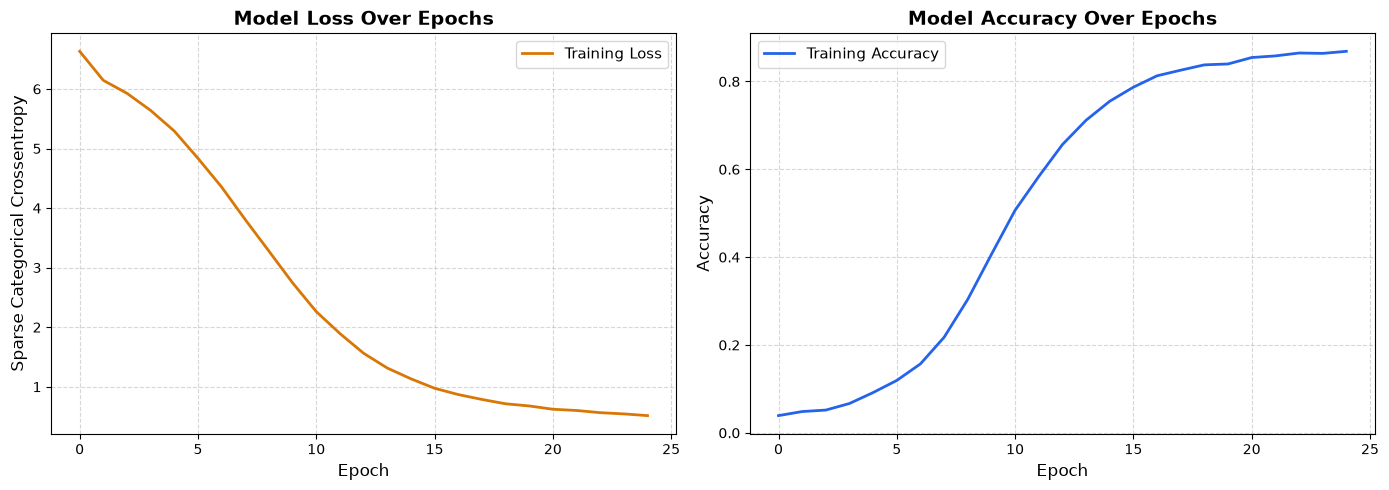

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve
ax1.plot(history.history['loss'], label='Training Loss', color='#D97706', linewidth=2)
ax1.set_title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Sparse Categorical Crossentropy', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=11)

# Accuracy Curve
ax2.plot(history.history['accuracy'], label='Training Accuracy', color='#2563EB', linewidth=2)
ax2.set_title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()


---
## 10. Multi-Word Prediction Engine
A critical requirement of our system is **multi-word prediction**:
Given a prompt (e.g., `"to be or not"`), predict the next $K$ consecutive words.

We implement:
1. **Iterative Token Generation**:
   - Tokenize and pre-pad current context string.
   - Run inference through LSTM.
   - Pick the predicted word (via greedy argmax or temperature sampling).
   - Append predicted word to current context string and repeat for $K$ steps.
2. **Temperature Sampling**:
   - `temperature < 0.1`: Deterministic greedy output (most likely word).
   - `temperature ~ 0.7`: Balanced creativity, natural Shakespearean style.
   - `temperature > 1.0`: High entropy, imaginative text diversity.
3. **Top-K Probability Inspector**:
   - Displays candidate words with their percentage confidence for each step.


In [16]:
def predict_next_words(seed_text, num_words=5, temperature=0.7, show_top_k=3):
    """
    Predicts the next `num_words` consecutive words starting from `seed_text`.
    """
    current_text = seed_text.strip().lower()
    predicted_tokens = []

    print(f"\n{'='*60}")
    print(f"🔮 Seed Prompt: '{seed_text}' | Generating Next {num_words} Words (Temp={temperature}):")
    print(f"{'='*60}")

    for step in range(num_words):
        # 1. Tokenize seed/current text
        token_list = tokenizer.texts_to_sequences([current_text])[0]
        # 2. Pre-pad sequence
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')
        # 3. Model forward pass
        preds = model.predict(token_list, verbose=0)[0]

        # Top candidates
        top_indices = np.argsort(preds)[::-1][:show_top_k]
        top_candidates = [(tokenizer.index_word.get(idx, '<OOV>'), float(preds[idx])) for idx in top_indices]

        # 4. Temperature sampling
        if temperature <= 0.05:
            predicted_id = int(np.argmax(preds))
        else:
            preds = np.asarray(preds).astype("float64")
            preds = np.log(preds + 1e-10) / temperature
            exp_preds = np.exp(preds)
            preds = exp_preds / np.sum(exp_preds)
            probas = np.random.multinomial(1, preds, 1)
            predicted_id = int(np.argmax(probas))

        output_word = tokenizer.index_word.get(predicted_id, "")
        if not output_word or output_word == "<OOV>":
            output_word = top_candidates[0][0]

        predicted_tokens.append(output_word)
        current_text += " " + output_word

        # Display step progress
        cand_str = ", ".join([f"'{w}' ({p*100:.1f}%)" for w, p in top_candidates])
        print(f"  Step {step+1:02d}: Predicted -> '{output_word:<10}' | Top Candidates: [{cand_str}]")

    print(f"\nFinal Output:")
    print(f"\033[1m{seed_text}\033[0m \033[93m{' '.join(predicted_tokens)}\033[0m")
    return current_text, predicted_tokens


---
## 11. Multi-Word Prediction Testing
Let's test our multi-word predictor with various Shakespearean seed prompts!


In [17]:
# Test 1: Classic Hamlet soliloquy prompt
predict_next_words("To be or not", num_words=6, temperature=0.5)

# Test 2: Sonnet prompt
predict_next_words("Shall I compare thee", num_words=7, temperature=0.7)

# Test 3: Citizen / Political prompt
predict_next_words("Good citizens hear me", num_words=5, temperature=0.6)

# Test 4: Dialogue prompt
predict_next_words("The king shall", num_words=6, temperature=0.8)



🔮 Seed Prompt: 'To be or not' | Generating Next 6 Words (Temp=0.5):
  Step 01: Predicted -> 'else      ' | Top Candidates: ['else' (75.5%), 'may' (2.2%), 'miles' (1.7%)]
  Step 02: Predicted -> 'do        ' | Top Candidates: ['do' (63.0%), 'have' (6.9%), 'shall' (5.8%)]
  Step 03: Predicted -> 'do        ' | Top Candidates: ['do' (68.4%), 'prize' (8.7%), 'receive' (3.4%)]
  Step 04: Predicted -> 'you       ' | Top Candidates: ['you' (97.7%), 'i' (0.9%), 'no' (0.2%)]
  Step 05: Predicted -> 'do        ' | Top Candidates: ['think' (37.2%), 'do' (14.4%), 'have' (10.7%)]
  Step 06: Predicted -> 'remember  ' | Top Candidates: ['remember' (36.3%), 'not' (23.8%), 'you' (5.5%)]

Final Output:
To be or not else do do you do remember

🔮 Seed Prompt: 'Shall I compare thee' | Generating Next 7 Words (Temp=0.7):
  Step 01: Predicted -> 'cannot    ' | Top Candidates: ['sir' (25.0%), 'alone' (13.1%), 'in' (9.9%)]
  Step 02: Predicted -> 'call      ' | Top Candidates: ['call' (61.0%), 'alone' (20.2%)

('the king shall our lady as yet he did',
 ['our', 'lady', 'as', 'yet', 'he', 'did'])

---
## 12. Model & Tokenizer Serialization for Streamlit UI
We export:
1. `shakespeare_lstm.keras` (Trained model weights and architecture)
2. `tokenizer.pkl` (Word $\leftrightarrow$ ID lookup table)
3. `config.json` (Max sequence length, vocabulary size, metadata)

These files power the interactive **Streamlit Web Application** (`app.py`).


In [18]:
MODEL_DIR = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Save Keras Model
model_path = os.path.join(MODEL_DIR, "shakespeare_lstm.keras")
model.save(model_path)
print(f"[+] Model saved to: {model_path}")

# 2. Save Tokenizer
tokenizer_path = os.path.join(MODEL_DIR, "tokenizer.pkl")
with open(tokenizer_path, "wb") as f:
    pickle.dump(tokenizer, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"[+] Tokenizer saved to: {tokenizer_path}")

# 3. Save Config
config_path = os.path.join(MODEL_DIR, "config.json")
config = {
    "max_sequence_len": int(max_sequence_len),
    "vocab_size": int(total_words),
    "embedding_dim": int(EMBEDDING_DIM),
    "lstm_units": int(LSTM_UNITS),
    "epochs": int(EPOCHS),
    "final_loss": float(history.history["loss"][-1]) if "history" in locals() and "loss" in history.history else None
}
with open(config_path, "w") as f:
    json.dump(config, f, indent=4)
print(f"[+] Config saved to: {config_path}")

print("\n[🎉 READY] All artifacts saved. You can now launch the web app with:")
print("streamlit run app.py")


[+] Model saved to: model\shakespeare_lstm.keras
[+] Tokenizer saved to: model\tokenizer.pkl
[+] Config saved to: model\config.json

[🎉 READY] All artifacts saved. You can now launch the web app with:
streamlit run app.py
